# Algèbre linéaire et probabilités en pratique

**Objectifs.** Lire vecteurs et matrices comme des formes de données, calculer produit scalaire et distance, interpréter une paire propre, résumer une variable aléatoire et appliquer Bayes. Durée : 75–100 min.

## 1. Vecteurs, normes et distances

Un vecteur peut encoder les mesures d’une observation. Le produit scalaire combine deux vecteurs coordonnée par coordonnée. La norme L2 mesure la longueur ; la distance euclidienne mesure l’écart. KNN utilise une distance, d’où l’importance de mettre les variables sur des échelles comparables.

In [ ]:
import numpy as np

observation = np.array([3.0, 4.0])
weights = np.array([0.6, 0.8])
other = np.array([0.0, 4.0])
print('shape:', observation.shape)
print('dot product:', observation @ weights)
print('L2 norm:', np.linalg.norm(observation))
print('distance:', np.linalg.norm(observation - other))

### Lire une distance dans le plan

Le vecteur `[3,4]` relie l'origine au point `(3,4)` et sa norme vaut 5. La distance entre deux observations est la norme de leur différence : ici `||(3,4)-(0,4)||₂ = 3`. Cette géométrie n'est pertinente pour comparer des clients ou des images que si les variables ont des unités et échelles adaptées.

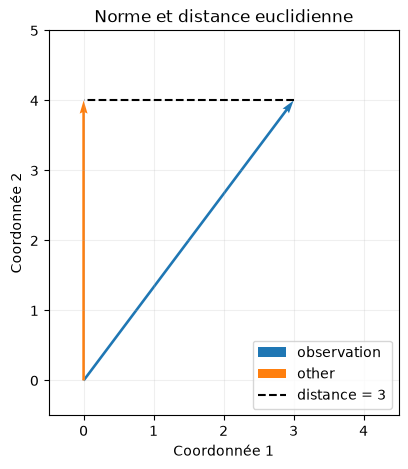

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
ax.quiver(0, 0, observation[0], observation[1], angles='xy', scale_units='xy', scale=1, color='tab:blue', label='observation')
ax.quiver(0, 0, other[0], other[1], angles='xy', scale_units='xy', scale=1, color='tab:orange', label='other')
ax.plot([observation[0], other[0]], [observation[1], other[1]], 'k--', label='distance = 3')
ax.set(xlim=(-0.5, 4.5), ylim=(-0.5, 5), xlabel='Coordonnée 1', ylabel='Coordonnée 2', title='Norme et distance euclidienne')
ax.set_aspect('equal'); ax.grid(alpha=0.2); ax.legend(); plt.show()

## 2. Matrices et produit matriciel

Si `A` a la forme `(n,p)` et `B` la forme `(p,q)`, alors `A @ B` a la forme `(n,q)`. En ML, les lignes sont souvent les exemples, tandis que colonnes sont variables ou unités cachées.

In [ ]:
A = np.array([[1.0, 2.0], [0.0, 1.0], [3.0, 1.0]])
B = np.array([[2.0, 0.0], [1.0, 4.0]])
print('A:', A.shape, 'B:', B.shape, 'A @ B:', (A @ B).shape)
print(A @ B)

## 3. Valeurs propres : directions qui restent alignées

Pour certaines matrices carrées `A`, un vecteur propre `v` conserve sa direction lors de la multiplication : `A @ v = lambda * v`. La valeur `lambda` donne l’étirement dans cette direction. PCA s’appuie sur les directions de variance d’une matrice de covariance.

In [ ]:
cov_like = np.array([[2.0, 1.0], [1.0, 2.0]])
eigenvalues, eigenvectors = np.linalg.eigh(cov_like)
print('eigenvalues:', eigenvalues.round(3))
print('eigenvectors are columns:\n', eigenvectors.round(3))
for index in range(len(eigenvalues)):
    vector = eigenvectors[:, index]
    print(np.allclose(cov_like @ vector, eigenvalues[index] * vector))

### Pourquoi PCA regarde ces directions

Pour des données centrées de covariance proche de `cov_like`, les points forment un nuage étiré. Le vecteur propre associé à la plus grande valeur propre donne la direction de plus grande variance. PCA projette le nuage sur de telles directions ; elle ne cherche pas à prédire la cible. Ici le nuage est simulé à partir d'une matrice connue.

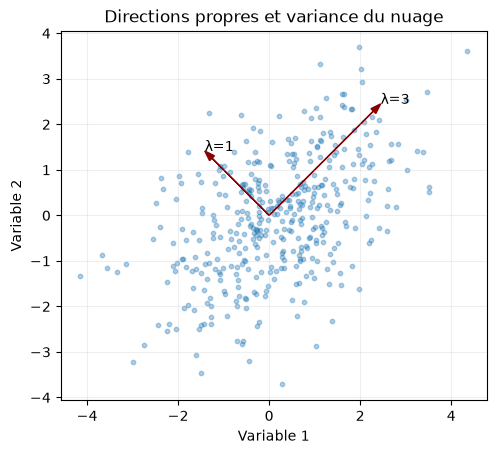

In [ ]:
eigen_rng = np.random.default_rng(7)
cloud = eigen_rng.multivariate_normal([0., 0.], cov_like, size=400)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(cloud[:, 0], cloud[:, 1], s=10, alpha=0.35, label='Observations simulées')
for value, direction in zip(eigenvalues, eigenvectors.T):
    span = 2 * np.sqrt(value) * direction
    ax.arrow(0, 0, span[0], span[1], head_width=0.15, color='darkred', length_includes_head=True)
    ax.text(span[0], span[1], f'λ={value:.0f}')
ax.set(xlabel='Variable 1', ylabel='Variable 2', title='Directions propres et variance du nuage')
ax.set_aspect('equal'); ax.grid(alpha=0.2); plt.show()

## 4. Moyenne, variance, covariance et corrélation

La moyenne résume le centre, la variance la dispersion autour du centre. La covariance décrit un changement conjoint mais son échelle dépend des unités ; la corrélation normalisée reste entre -1 et 1. Corrélation ne signifie pas causalité.

In [ ]:
rng = np.random.default_rng(19)
x = rng.normal(10, 2, size=500)
y = 0.7 * x + rng.normal(0, 1.4, size=500)
print('mean/std x:', round(x.mean(), 2), round(x.std(), 2))
print('covariance matrix:\n', np.cov(np.column_stack([x, y])).round(2))
print('correlation:', round(float(np.corrcoef(x, y)[0, 1]), 3))

## 5. Bayes et base rates

Bayes inverse une probabilité conditionnelle : \(P(A|B)=P(B|A)P(A)/P(B)\). Exemple fictif : un signal rare a une prévalence de 1 %, un test détecte 95 % des cas et produit 10 % de faux positifs chez les non-cas. Parmi les alertes, la proportion de vrais cas dépend aussi de cette prévalence.

In [ ]:
prevalence = 0.01
sensitivity = 0.95
false_positive_rate = 0.10
true_positive_rate = sensitivity * prevalence
all_positive_rate = true_positive_rate + false_positive_rate * (1 - prevalence)
posterior = true_positive_rate / all_positive_rate
print('probability of condition after positive signal:', round(posterior, 3))

### Visualisation du taux de base

Sur 10 000 cas fictifs avec prévalence 1 %, on attend environ 95 vrais positifs (100 × 0,95) et 990 faux positifs (9 900 × 0,10). Une alerte positive n'a donc qu'environ 95 / (95+990) ≈ 8,8 % de chance d'être un vrai cas dans cet exemple. La même sensibilité et le même taux de faux positifs donnent une autre lecture si la prévalence change.

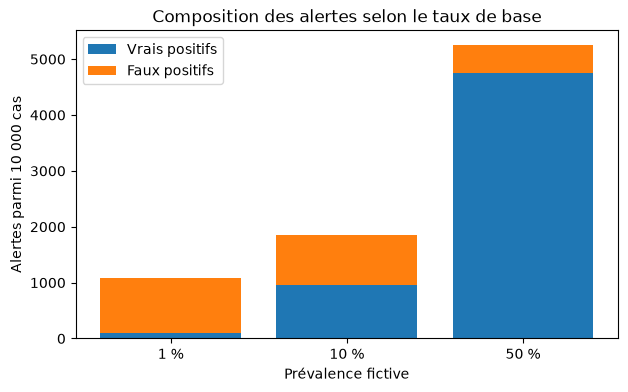

In [ ]:
base_rates = np.array([0.01, 0.10, 0.50])
true_alerts = 10_000 * base_rates * sensitivity
false_alerts = 10_000 * (1 - base_rates) * false_positive_rate
fig, ax = plt.subplots(figsize=(7, 4))
positions = np.arange(len(base_rates))
ax.bar(positions, true_alerts, label='Vrais positifs')
ax.bar(positions, false_alerts, bottom=true_alerts, label='Faux positifs')
ax.set(xticks=positions, xticklabels=['1 %', '10 %', '50 %'], xlabel='Prévalence fictive', ylabel='Alertes parmi 10 000 cas', title='Composition des alertes selon le taux de base')
ax.legend(); plt.show()
print('Part de vrais positifs parmi les alertes :', np.round(true_alerts / (true_alerts + false_alerts), 3))

## Interprétation et limites

Une sensibilité élevée ne garantit pas une valeur prédictive positive élevée lorsque le phénomène est rare. L’exemple est mathématique et n’est pas un conseil médical. Les matrices, distributions et formules doivent être adaptées au plan d’échantillonnage réel.

À réviser ensuite : [`01_gradient_descent.ipynb`](01_gradient_descent.ipynb) pour le gradient et la loss. Exercices : [`02_gradients.ipynb`](../../exercises/intermediate/02_gradients.ipynb).